# Задача 1. Тележка на пружине без трения

### Условие

масса m = 1 кг\
начальное смещение X0 = 0.1 м, начальная скорость V0 = 0 м/с\
жёсткости k = 1, 4, 9, 16, 25 Н/м\
временной интервал для графиков t[0: 10] c

### Решение ДУ

Подключение библиотек

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

Символьные переменные

In [7]:
t, m, k = sp.symbols('t m k', positive=True)
x = sp.Function('x')

ДУ

In [9]:
ode_x = sp.Eq(m*sp.diff(x(t), t, 2) + k*x(t), 0)
sp.pprint(ode_x)

             2          
            d           
k⋅x(t) + m⋅───(x(t)) = 0
             2          
           dt           


Параметры

In [21]:
m_val = 1
k_values = [1, 4, 9, 16, 25]
x0 = 0.1
v0 = 0
n_points = 1000
general_solutions = {}
part_solutions = {}
speed_solutions = {}

In [23]:
for k_val in k_values:
    ode = sp.Eq(m_val * sp.diff(x(t), t, 2) + k_val * x(t), 0)

    # Общее решение
    sol_general = sp.dsolve(ode)
    general_solutions[k_val] = sol_general

    # Частное решение
    sol_part = sp.dsolve(ode, ics={x(0): x0, sp.diff(x(t), t).subs(t, 0): v0})
    part_solutions[k_val] = sol_part

    # Скорость
    v_expr = sp.simplify(sp.diff(sol_part.rhs, t))
    speed_solutions[k_val] = v_expr
print("----Общее решение----")
for k_val in k_values:
    print(f"k = {k_val}:")
    sp.pprint(general_solutions[k_val])
    print()

print("----Частное решение----")
for k_val in k_values:
    print(f"k = {k_val}:")
    sp.pprint(part_solutions[k_val])
    print()

----Общее решение----
k = 1:
x(t) = C₁⋅sin(t) + C₂⋅cos(t)

k = 4:
x(t) = C₁⋅sin(2⋅t) + C₂⋅cos(2⋅t)

k = 9:
x(t) = C₁⋅sin(3⋅t) + C₂⋅cos(3⋅t)

k = 16:
x(t) = C₁⋅sin(4⋅t) + C₂⋅cos(4⋅t)

k = 25:
x(t) = C₁⋅sin(5⋅t) + C₂⋅cos(5⋅t)

----Частное решение----
k = 1:
x(t) = 0.1⋅cos(t)

k = 4:
x(t) = 0.1⋅cos(2⋅t)

k = 9:
x(t) = 0.1⋅cos(3⋅t)

k = 16:
x(t) = 0.1⋅cos(4⋅t)

k = 25:
x(t) = 0.1⋅cos(5⋅t)



### Построение графиков

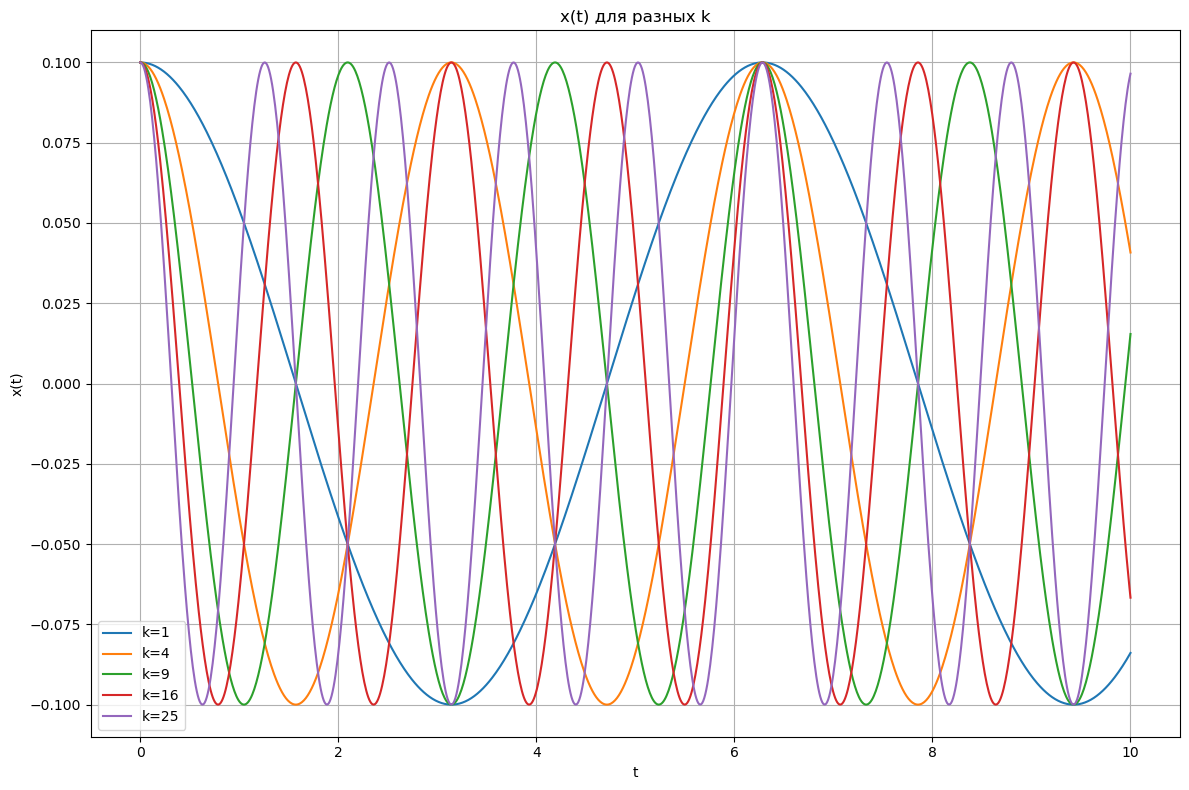

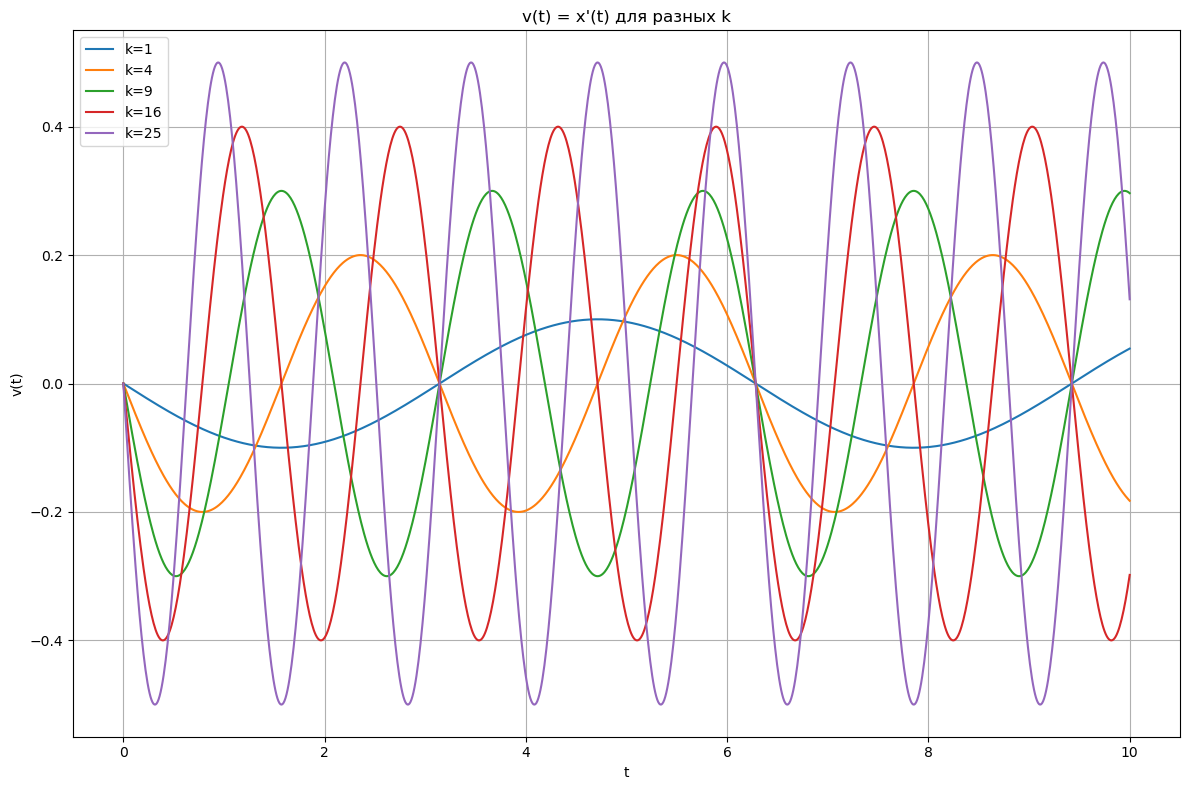

In [34]:
t_vals = np.linspace(0, 10, n_points)

x_funcs = {}
v_funcs = {}

for k_val in k_values:
    x_expr = sp.simplify(part_solutions[k_val].rhs)
    v_expr = speed_solutions[k_val]

    x_funcs[k_val] = sp.lambdify(t, x_expr, 'numpy')
    v_funcs[k_val] = sp.lambdify(t, v_expr, 'numpy')
    
# ГРАФИК x(t)

plt.figure(figsize=(12, 8))
for k_val in k_values:
    plt.plot(t_vals, x_funcs[k_val](t_vals), label=f'k={k_val}')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('x(t) для разных k')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ГРАФИК v(t)

plt.figure(figsize=(12, 8))
for k_val in k_values:
    plt.plot(t_vals, v_funcs[k_val](t_vals), label=f'k={k_val}')
plt.xlabel('t')
plt.ylabel('v(t)')
plt.title("v(t) = x'(t) для разных k")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#### Фазовый портрет

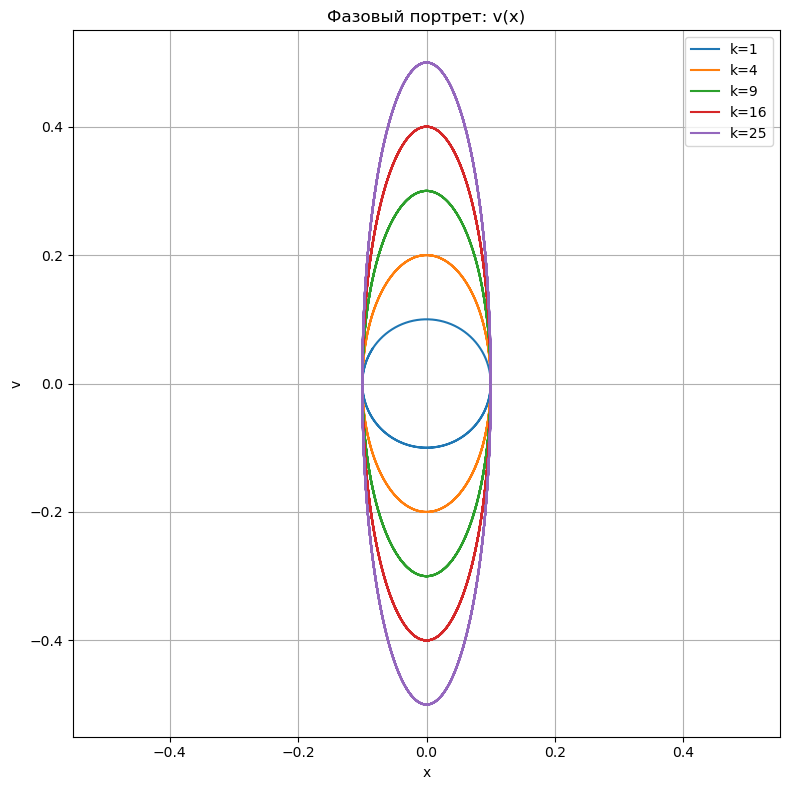

In [37]:
plt.figure(figsize=(8, 8))
for k_val in k_values:
    x_num = x_funcs[k_val](t_vals)
    v_num = v_funcs[k_val](t_vals)
    plt.plot(x_num, v_num, label=f'k={k_val}')
plt.xlabel('x')
plt.ylabel('v')
plt.title('Фазовый портрет: v(x)')
plt.grid(True)
plt.legend()
plt.axis('equal')
plt.tight_layout()
plt.show()

In [44]:
def calc_period(t_arr, y_arr):
    peaks_t = []
    for i in range(1, len(y_arr) - 1):
# Нахождение лок максимумов
        if (y_arr[i] > y_arr[i - 1]) and (y_arr[i] > y_arr[i + 1]):
            peaks_t.append(t_arr[i])

    peaks_t = np.array(peaks_t)
# С помощью diff(peaks_t) найдём расстояние между соседними максимумами
    if len(peaks_t) < 2:
        return np.nan
    return np.mean(np.diff(peaks_t))

print("----Периоды----")
for k_val in k_values:
    x_num = x_funcs[k_val](t_vals)
    T = calc_period(t_vals, x_num)
    T_theory = 2 * np.pi * np.sqrt(m_val / k_val)
    print(f"k={k_val}: T_график = {T:.6f}, T_теор = {T_theory:.6f}")

----Периоды----
k=1: T_график = nan, T_теор = 6.283185
k=4: T_график = 3.143143, T_теор = 3.141593
k=9: T_график = 2.095429, T_теор = 2.094395
k=16: T_график = 1.571572, T_теор = 1.570796
k=25: T_график = 1.256256, T_теор = 1.256637


Так как по условию система замкнутая, T (период) получается близким к периоду мат маятника (вероятно погрешность вычислений numpy)